# Evaluation and PCA ablation (T13)

This notebook reads results written by three scripts. It does not train anything itself.

| Script | Writes |
|---|---|
| `reports/results/run_baselines.py` | `baselines.json`: random, heuristic and MCTS |
| `scripts/train.py --name main` | `models/main/`: the main model and its evaluation |
| `reports/results/run_ablation.py` | `ablation.csv`: five card representations under equal budgets and several seeds |

Win rates count a draw as half a win. Intervals are 95% Wilson intervals.

**Success threshold.** It must be set by a person *before* training (task H5). It is not set yet, so this notebook
gives no pass or fail verdict. Set `THRESHOLD` below once H5 is decided.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tcg_bot.paths import REPORTS, ROOT
from tcg_bot.evaluate import wilson

THRESHOLD = None          # set by H5, e.g. {"opponent": "heuristic", "win_rate": 0.55}, BEFORE looking at results
RES = REPORTS / "results"
FIG = REPORTS / "figures"; FIG.mkdir(exist_ok=True)
base = json.loads((RES / "baselines.json").read_text())
main_eval = json.loads((ROOT / "models" / "main" / "eval.json").read_text())
main_cfg = json.loads((ROOT / "models" / "main" / "config.json").read_text())
abl = pd.read_csv(RES / "ablation.csv")
print("rule assumptions used in every game:", base["settings_assumptions"])

rule assumptions used in every game: {'mega_evolution_ends_turn': False, 'mega_ex_prize_value': 3, 'resistance_amount': 30, 'may_end_turn_without_attack': True, 'effect_attach_uses_hand_attach': False, 'bottom_of_deck_order': 'random', 'search_may_find_fewer': True, 'recoil_applies_weakness_resistance': False, 'take_mulligan_bonus_cards': True}


## 1. Baselines and the main model

In [2]:
rows = []
for m in base["matches"]:
    rows.append({"player": m["a"], "opponent": m["b"].replace("_b", ""), "games": m["games"], "win rate": m["a_win_rate"],
                 "95% CI": tuple(m["ci95"]), "s per searched move": m.get("mcts_seconds_per_searched_move", "")})
for opp, m in main_eval.items():
    rows.append({"player": "model (main)", "opponent": opp, "games": m["games"], "win rate": m["a_win_rate"],
                 "95% CI": tuple(m["ci95"]), "s per searched move": ""})
league = pd.DataFrame(rows)
print(league.to_string(index=False))
print("\nmain model training:", main_cfg["iterations"] * main_cfg["games_per_iter"], "games, seed", main_cfg["seed"],
      "| card input:", main_cfg["card_repr"], "+ identity" if main_cfg["use_identity"] else "")

      player  opponent  games  win rate         95% CI s per searched move
      random    random    400     0.535 (0.486, 0.583)                    
   heuristic    random    400     0.877 (0.842, 0.906)                    
        mcts    random     20     0.900 (0.699, 0.972)               0.856
        mcts heuristic     20     0.800 (0.584, 0.919)               0.984
model (main)    random    200     0.960  (0.923, 0.98)                    
model (main) heuristic    200     0.415 (0.349, 0.484)                    

main model training: 3200 games, seed 0 | card input: pca_bypass + identity


## 2. PCA ablation: equal training budget, several seeds

In [3]:
g = abl.groupby(["variant", "opponent"])
summary = g.agg(seeds=("seed", "nunique"), train_games=("train_games", "first"), mean=("win_rate", "mean"),
                sd=("win_rate", "std"), wins=("win_rate", lambda s: float((s * abl.loc[s.index, "eval_games"]).sum())),
                n=("eval_games", "sum")).reset_index()
summary["pooled 95% CI"] = [tuple(round(x, 3) for x in wilson(w, int(n))) for w, n in zip(summary["wins"], summary["n"])]
order = ["pca_only", "pca_bypass", "pca_bypass_identity", "raw_columns", "learned_embedding"]
summary["variant"] = pd.Categorical(summary["variant"], order, ordered=True)
summary = summary.sort_values(["opponent", "variant"])
print(summary.drop(columns=["wins"]).round(3).to_string(index=False))

            variant  opponent  seeds  train_games  mean    sd   n  pooled 95% CI
           pca_only heuristic      3          640 0.240 0.044 300 (0.195, 0.291)
         pca_bypass heuristic      3          640 0.227 0.055 300 (0.183, 0.277)
pca_bypass_identity heuristic      3          640 0.307 0.083 300 (0.257, 0.361)
        raw_columns heuristic      3          640 0.303 0.023 300 (0.254, 0.358)
  learned_embedding heuristic      3          640 0.227 0.038 300 (0.183, 0.277)
           pca_only    random      3          640 0.903 0.006 300 (0.865, 0.932)
         pca_bypass    random      3          640 0.913 0.040 300  (0.876, 0.94)
pca_bypass_identity    random      3          640 0.933 0.038 300 (0.899, 0.956)
        raw_columns    random      3          640 0.943 0.035 300 (0.911, 0.964)
  learned_embedding    random      3          640 0.853 0.047 300 (0.809, 0.889)


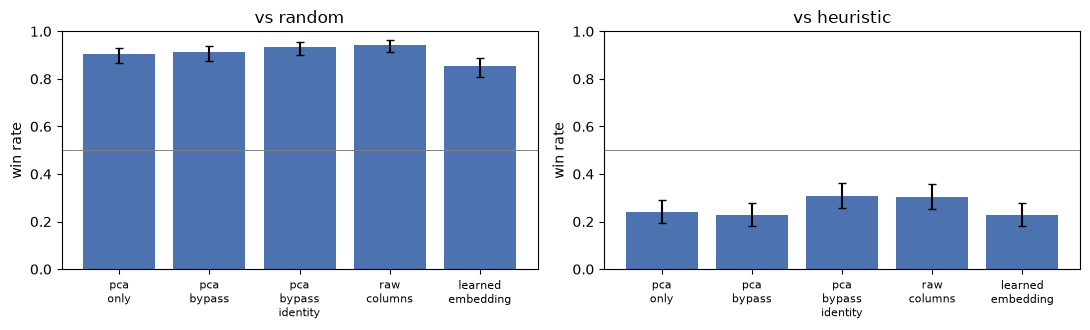

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=False)
for a, opp in zip(ax, ["random", "heuristic"]):
    s = summary[summary["opponent"] == opp]
    lo = [m - ci[0] for m, ci in zip(s["mean"], s["pooled 95% CI"])]
    hi = [ci[1] - m for m, ci in zip(s["mean"], s["pooled 95% CI"])]
    a.bar(range(len(s)), s["mean"], yerr=[lo, hi], capsize=3, color="#4c72b0")
    a.set_xticks(range(len(s))); a.set_xticklabels([str(v).replace("_", "\n") for v in s["variant"]], fontsize=8)
    a.axhline(0.5, color="grey", lw=0.7); a.set_ylim(0, 1); a.set_title(f"vs {opp}"); a.set_ylabel("win rate")
plt.tight_layout(); fig.savefig(FIG / "ablation.png", dpi=110); plt.show()

## 3. Does the PCA help?

In [5]:
def best(opp):
    s = summary[summary["opponent"] == opp].set_index("variant")
    return s
for opp in ("random", "heuristic"):
    s = best(opp)
    ref = s.loc["raw_columns"]
    for v in ("pca_only", "pca_bypass", "pca_bypass_identity", "learned_embedding"):
        ci, rci = s.loc[v, "pooled 95% CI"], ref["pooled 95% CI"]
        overlap = not (ci[0] > rci[1] or ci[1] < rci[0])
        print(f"vs {opp:9s} {v:20s} {s.loc[v, 'mean']:.3f} vs raw {ref['mean']:.3f} ->",
              "intervals overlap: no clear difference" if overlap else ("better" if ci[0] > rci[1] else "worse"))

vs random    pca_only             0.903 vs raw 0.943 -> intervals overlap: no clear difference
vs random    pca_bypass           0.913 vs raw 0.943 -> intervals overlap: no clear difference
vs random    pca_bypass_identity  0.933 vs raw 0.943 -> intervals overlap: no clear difference
vs random    learned_embedding    0.853 vs raw 0.943 -> worse
vs heuristic pca_only             0.240 vs raw 0.303 -> intervals overlap: no clear difference
vs heuristic pca_bypass           0.227 vs raw 0.303 -> intervals overlap: no clear difference
vs heuristic pca_bypass_identity  0.307 vs raw 0.303 -> intervals overlap: no clear difference
vs heuristic learned_embedding    0.227 vs raw 0.303 -> intervals overlap: no clear difference


Read this table literally. If the intervals overlap, the ablation does **not** show that PCA helps or hurts at this
training budget. That is a valid result, and the paper should report it as one.

## 4. Threshold verdict

In [6]:
if THRESHOLD is None:
    print("No verdict: the success threshold has not been set (task H5). It must be fixed before training.")
else:
    m = main_eval[THRESHOLD["opponent"]]
    lo = m["ci95"][0]
    print(f"main model vs {THRESHOLD['opponent']}: {m['a_win_rate']:.3f}, CI low {lo:.3f}, threshold {THRESHOLD['win_rate']}")
    print("PASS" if lo >= THRESHOLD["win_rate"] else "FAIL (or not shown at 95%)")

No verdict: the success threshold has not been set (task H5). It must be fixed before training.


## 5. Training curve of the main model

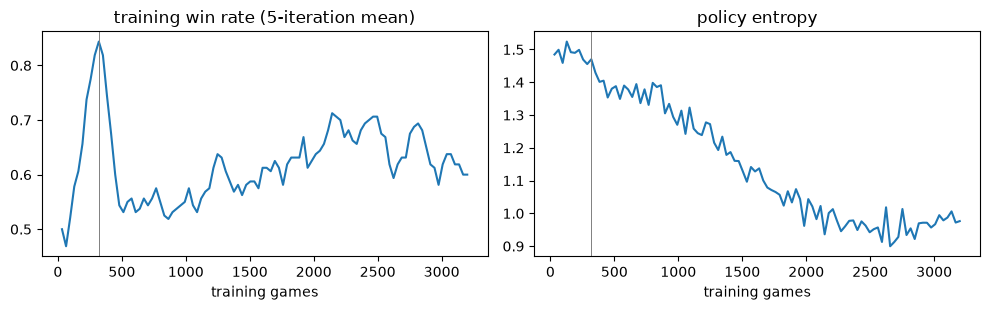

the grey line marks the switch from the fixed random opponent to the rotation (random, heuristic, snapshots)


In [7]:
h = pd.read_csv(ROOT / "models" / "main" / "metrics.csv")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(h["games"], h["train_win_rate"].rolling(5, min_periods=1).mean()); ax[0].set_title("training win rate (5-iteration mean)")
ax[1].plot(h["games"], h["entropy"]); ax[1].set_title("policy entropy")
for a in ax: a.set_xlabel("training games"); a.axvline(main_cfg["stage1_iters"] * main_cfg["games_per_iter"], color="grey", lw=0.7)
plt.tight_layout(); fig.savefig(FIG / "training_curve.png", dpi=110); plt.show()
print("the grey line marks the switch from the fixed random opponent to the rotation (random, heuristic, snapshots)")